# Laboratorium 04: MLP i SimpleCNN na CIFAR-10



In [ ]:
!pip install torch torchvision matplotlib

In [ ]:
import copy
import math
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

CFG = {"epochs": 10, "lr": 1e-3, "batch_size": 128, "seed": 42}
torch.manual_seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Urządzenie:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Uwaga: włącz GPU w ustawieniach Google Colab.")

Urządzenie: cuda
GPU: Tesla T4


## Dane i modele

In [ ]:
archive = Path("/content/cifar-10-python.tar.gz")
if archive.is_file():
    Path("data").mkdir(exist_ok=True)
    shutil.copyfile(archive, Path("data") / archive.name)

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_full = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=tf)
test_ds = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf)

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full), generator=g).tolist()
val_idx, train_idx = perm[:5000], perm[5000:]
train_ds = Subset(train_full, train_idx)
val_ds = Subset(train_full, val_idx)

train_dl = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, num_workers=2)
train_eval_dl = DataLoader(train_ds, batch_size=256, shuffle=False, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)

print("Trening:", len(train_ds), "| Walidacja:", len(val_ds), "| Test:", len(test_ds))

100%|██████████| 170M/170M [16:58<00:00, 167kB/s]


Trening: 45000 | Walidacja: 5000 | Test: 10000


In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.net(x)


def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.MaxPool2d(2),
    )


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters())


mlp_tmp, cnn_tmp = MLP(), SimpleCNN()
print("MLP:", count_params(mlp_tmp))
print("CNN - część splotowa:", count_params(cnn_tmp.features))
print("CNN - głowica:", count_params(cnn_tmp.classifier))
print("CNN - razem:", count_params(cnn_tmp))

MLP: 1707274
CNN - część splotowa: 65952
CNN - głowica: 1051402
CNN - razem: 1117354


## Testy kontrolne

In [ ]:
cnn_tmp = SimpleCNN()
x = torch.randn(2, 3, 32, 32)
for i, layer in enumerate(cnn_tmp.features):
    x = layer(x)
    print("Blok", i + 1, tuple(x.shape))
print("Wyjście:", tuple(cnn_tmp.classifier(x).shape))

crit = nn.CrossEntropyLoss()
xb, yb = next(iter(train_dl))
for name, model in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    model = model.to(device).eval()
    with torch.no_grad():
        loss = crit(model(xb.to(device)), yb.to(device)).item()
    print(f"{name}: strata na starcie {loss:.3f}, oczekiwane ok. {math.log(10):.3f}")

model = SimpleCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
x32, y32 = xb[:32].to(device), yb[:32].to(device)
model.train()
for step in range(101):
    opt.zero_grad()
    loss = crit(model(x32), y32)
    loss.backward()
    opt.step()
    if step % 25 == 0:
        print(f"Krok {step}: strata {loss.item():.4f}")

Blok 1 (2, 32, 16, 16)
Blok 2 (2, 64, 8, 8)
Wyjście: (2, 10)
MLP: strata na starcie 2.310, oczekiwane ok. 2.303
CNN: strata na starcie 2.300, oczekiwane ok. 2.303
Krok 0: strata 2.2518
Krok 25: strata 0.0032
Krok 50: strata 0.0004
Krok 75: strata 0.0003
Krok 100: strata 0.0002


## Trening, porównanie i wykresy

In [ ]:
def sync():
    if device == "cuda":
        torch.cuda.synchronize()


def train_one_epoch(model, dl, opt, crit):
    model.train()
    s = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        opt.step()
        s += loss.item() * yb.size(0)
        n += yb.size(0)
    return s / n


@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval()
    s = c = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item()
        n += yb.size(0)
    return s / n, c / n


def fit(model):
    torch.manual_seed(CFG["seed"])
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1, "epoch": 0, "state": None}
    train_time = eval_time = 0.0

    for epoch in range(1, CFG["epochs"] + 1):
        sync()
        t0 = time.time()
        train_one_epoch(model, train_dl, opt, crit)
        sync()
        t1 = time.time()

        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        sync()
        t2 = time.time()

        train_time += t1 - t0
        eval_time += t2 - t1
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)

        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": epoch,
                    "state": copy.deepcopy(model.state_dict())}

        print(f"Epoka {epoch:2d} | loss tr {tr_loss:.3f}, wal {va_loss:.3f}"
              f" | acc tr {tr_acc * 100:.2f}%, wal {va_acc * 100:.2f}%")

    model.load_state_dict(best["state"])
    return {"model": model, "hist": hist, "best": best,
            "train_time": train_time, "eval_time": eval_time}

In [ ]:
torch.manual_seed(CFG["seed"])
print("== MLP ==")
res_mlp = fit(MLP())

torch.manual_seed(CFG["seed"])
print("\n== SimpleCNN ==")
res_cnn = fit(SimpleCNN())

== MLP ==
Epoka  1 | loss tr 1.445, wal 1.520 | acc tr 49.02%, wal 45.88%
Epoka  2 | loss tr 1.326, wal 1.454 | acc tr 53.50%, wal 49.16%
Epoka  3 | loss tr 1.193, wal 1.376 | acc tr 58.19%, wal 52.06%
Epoka  4 | loss tr 1.176, wal 1.459 | acc tr 58.20%, wal 49.32%
Epoka  5 | loss tr 1.044, wal 1.395 | acc tr 63.27%, wal 52.56%
Epoka  6 | loss tr 0.977, wal 1.418 | acc tr 65.44%, wal 52.12%
Epoka  7 | loss tr 0.889, wal 1.419 | acc tr 68.69%, wal 52.30%
Epoka  8 | loss tr 0.843, wal 1.476 | acc tr 70.19%, wal 53.04%
Epoka  9 | loss tr 0.778, wal 1.546 | acc tr 72.58%, wal 51.40%
Epoka 10 | loss tr 0.700, wal 1.582 | acc tr 75.30%, wal 52.66%

== SimpleCNN ==
Epoka  1 | loss tr 1.006, wal 1.025 | acc tr 63.85%, wal 63.06%
Epoka  2 | loss tr 0.827, wal 0.875 | acc tr 71.43%, wal 69.74%
Epoka  3 | loss tr 0.673, wal 0.763 | acc tr 75.75%, wal 73.20%
Epoka  4 | loss tr 0.597, wal 0.711 | acc tr 78.73%, wal 75.02%
Epoka  5 | loss tr 0.533, wal 0.693 | acc tr 80.68%, wal 75.44%
Epoka  6 | lo

In [ ]:
crit = nn.CrossEntropyLoss()
rows = []
for name, r in [("MLP", res_mlp), ("CNN", res_cnn)]:
    m, h, b = r["model"], r["hist"], r["best"]
    _, test_acc = evaluate(m, test_dl, crit)
    i = b["epoch"] - 1
    rows.append((name, count_params(m), b["epoch"], h["train_acc"][i],
                 b["val_acc"], test_acc,
                 h["train_acc"][i] - b["val_acc"], r["train_time"]))

print("| Model | Parametry | Najlepsza epoka | Acc train | Acc walidacja |"
      " Acc test | Przerwa train-wal | Czas treningu [s] |")
print("|---|---:|---:|---:|---:|---:|---:|---:|")
for name, params, ep, tr, va, te, gap, t in rows:
    print(f"| {name} | {params:,} | {ep} | {tr*100:.2f}% | {va*100:.2f}% |"
          f" {te*100:.2f}% | {gap*100:.2f} p.p. | {t:.1f} |")
print(f"CNN: sploty {count_params(res_cnn['model'].features):,}; "
      f"głowica {count_params(res_cnn['model'].classifier):,}")
print("Czasy nie zawierają ewaluacji; klasyfikator losowy: 10%")

| Model | Parametry | Najlepsza epoka | Acc train | Acc walidacja | Acc test | Przerwa train-wal | Czas treningu [s] |
|---|---:|---:|---:|---:|---:|---:|---:|
| MLP | 1,707,274 | 8 | 70.19% | 53.04% | 52.64% | 17.15 p.p. | 106.9 |
| CNN | 1,117,354 | 10 | 89.76% | 79.94% | 78.57% | 9.82 p.p. | 120.5 |
CNN: sploty 65,952; głowica 1,051,402
Czasy nie zawierają ewaluacji; klasyfikator losowy: 10%


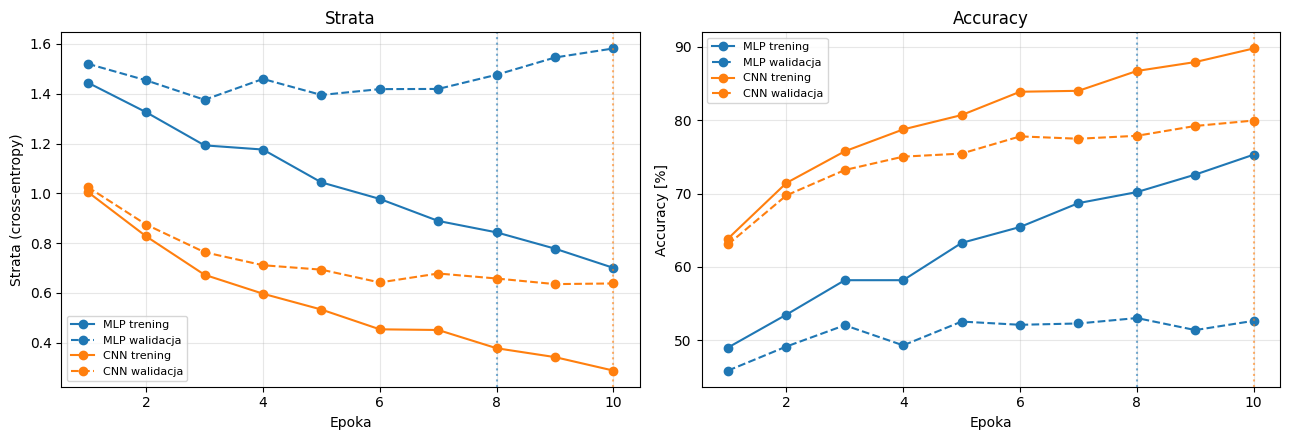

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r, color in [("MLP", res_mlp, "tab:blue"), ("CNN", res_cnn, "tab:orange")]:
    h = r["hist"]
    ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "-o", color=color, label=f"{name} trening")
    ax1.plot(ep, h["val_loss"], "--o", color=color, label=f"{name} walidacja")
    ax2.plot(ep, [a * 100 for a in h["train_acc"]], "-o", color=color,
             label=f"{name} trening")
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], "--o", color=color,
             label=f"{name} walidacja")
    for ax in (ax1, ax2):
        ax.axvline(r["best"]["epoch"], color=color, ls=":", alpha=0.6)

ax1.set(xlabel="Epoka", ylabel="Strata (cross-entropy)", title="Strata")
ax2.set(xlabel="Epoka", ylabel="Accuracy [%]", title="Accuracy")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("wykres_lab04.png", dpi=160, bbox_inches="tight")
plt.show()